In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
TOP_N = 10
BAR_FIGSIZE = (10, 6)
HEATMAP_FIGSIZE = (8, 6)
LEVEL_ORDER = ["EN", "MI", "SE", "EX"]

COUNTRY_NAMES = {
    "US": "USA", "GB": "United Kingdom", "CA": "Canada", "ES": "Spain",
    "IN": "India", "DE": "Germany", "FR": "France", "GR": "Greece",
    "PT": "Portugal", "BR": "Brazil", "NL": "Netherlands", "AU": "Australia",
    "JP": "Japan", "PL": "Poland",
}


def top_n_median(data, category_col, value_col, n=TOP_N):
    """Median of value_col for the n most frequent categories, sorted ascending."""
    top = data[category_col].value_counts().head(n).index
    subset = data[data[category_col].isin(top)]
    return subset.groupby(category_col)[value_col].median().sort_values()

# Анализ зарплат в Data Science 2021–2023

In [22]:
df = pd.read_csv("Data Science Salary 2021 to 2023.csv")

## График 1. Медианная зарплата по должностям

**Что визуализировано:** медианная зарплата (`salary_in_usd`) для топ-10
самых частых должностей. Горизонтальный столбчатый график, отсортирован
по возрастанию; взята медиана, а не среднее, чтобы снизить влияние выбросов.

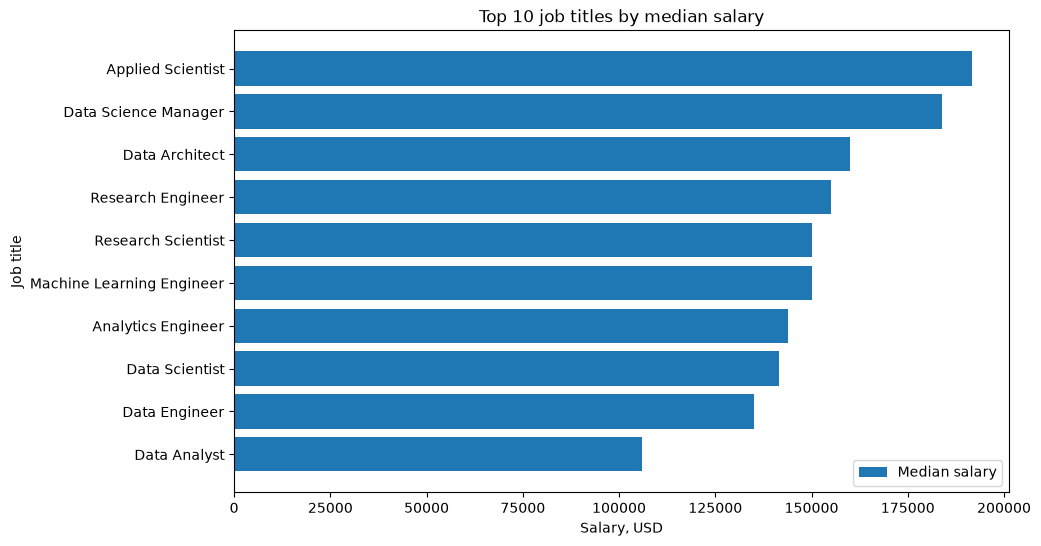

In [23]:
median_by_job = top_n_median(df, "job_title", "salary_in_usd")

fig, ax = plt.subplots(figsize=BAR_FIGSIZE)
ax.barh(median_by_job.index, median_by_job.values, label="Median salary")
ax.set_xlabel("Salary, USD")
ax.set_ylabel("Job title")
ax.set_title("Top 10 job titles by median salary")
ax.legend()
plt.show()

**Выводы:**
- Самые высокооплачиваемые роли - исследовательские и управленческие:
  Applied Scientist, Data Science Manager, Data Architect.
- Самые низкооплачиваемые среди топ-10 - массовые прикладные роли:
  Data Analyst и Data Engineer
- Разрыв между верхней и нижней должностью значительный, значит сама
  должность сильно влияет на оплату.

## График 2. Медианная зарплата по должностям и уровням опыта

**Что визуализировано:** тепловая карта (heatmap) медианной зарплаты
(`salary_in_usd`) для топ-10 должностей в разрезе уровней опыта
(EN MI SE EX). Строки - должности, столбцы - уровни, цвет и число
в клетке - медианная зарплата. Чем темнее клетка, тем выше зарплата.

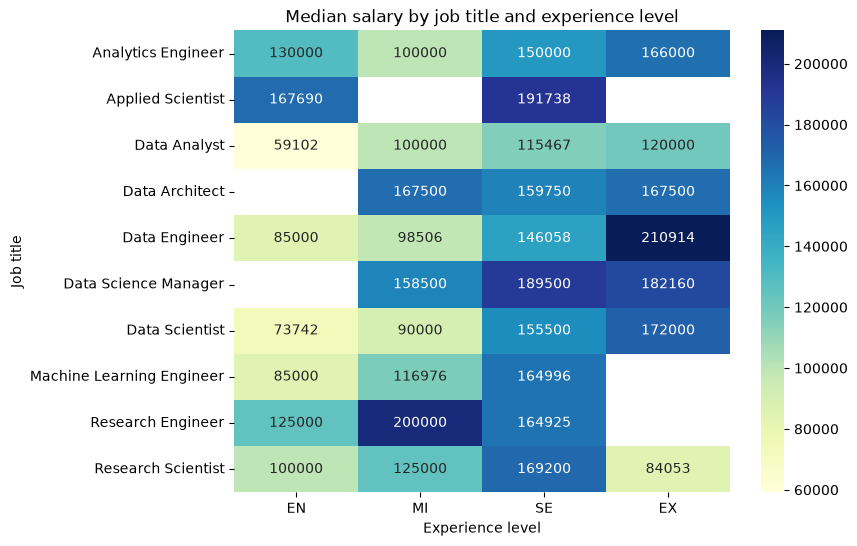

In [24]:
top_jobs = df["job_title"].value_counts().head(TOP_N).index
jobs_df = df[df["job_title"].isin(top_jobs)]

salary_pivot = jobs_df.pivot_table(
    index="job_title",
    columns="experience_level",
    values="salary_in_usd",
    aggfunc="median",
)
salary_pivot = salary_pivot[LEVEL_ORDER]

fig, ax = plt.subplots(figsize=HEATMAP_FIGSIZE)
sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax)
ax.set_xlabel("Experience level")
ax.set_ylabel("Job title")
ax.set_title("Median salary by job title and experience level")
plt.show()

**Выводы:**
- В целом зарплата растёт с опытом: по большинству должностей клетки
  темнеют слева направо (EN самый светлый, SE/EX - тёмные).
- Наибольший рост даёт переход от начального уровня (EN) к старшему (SE).
- Пустые клетки - сочетания «должность + уровень», которых нет в данных.
- Аномалии, где EX ниже SE, связаны с малым числом записей на уровне EX:
  медиана по 1-2 значениям неустойчива, доверять таким клеткам нельзя.

## График 3. Медианная зарплата по странам

**Что визуализировано:** медианная зарплата (`salary_in_usd`) по топ-10
странам с наибольшим числом записей (`company_location`). Столбчатый график,
отсортирован по возрастанию. Взяты только топ-10 стран по количеству данных,
чтобы медиана была устойчивой.

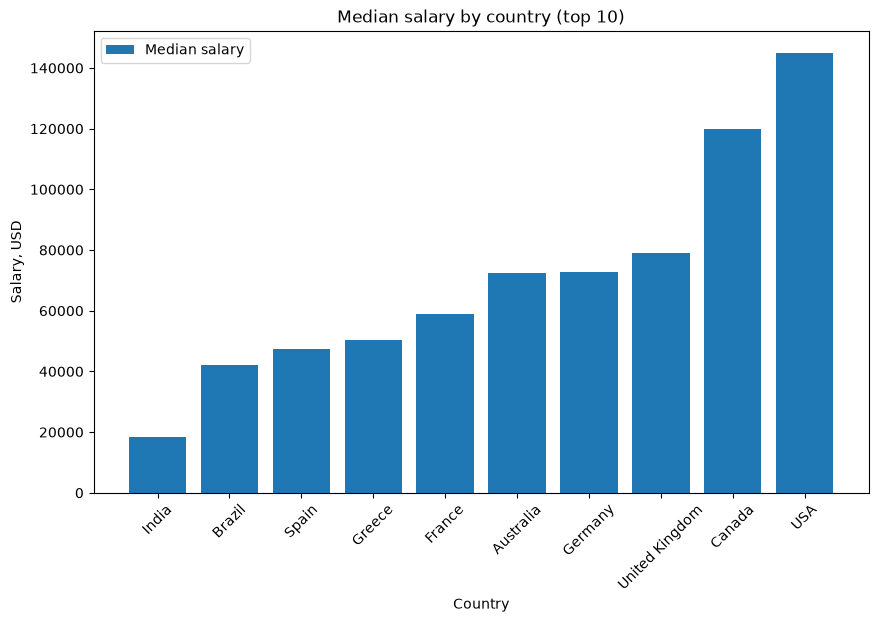

In [25]:
median_by_country = top_n_median(df, "company_location", "salary_in_usd")
median_by_country.index = median_by_country.index.map(
    lambda code: COUNTRY_NAMES.get(code, code)
)

fig, ax = plt.subplots(figsize=BAR_FIGSIZE)
ax.bar(median_by_country.index, median_by_country.values, label="Median salary")
ax.set_xlabel("Country")
ax.set_ylabel("Salary, USD")
ax.set_title("Median salary by country (top 10)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.show()

**Выводы:**
- Разброс зарплат между странами большой - лидер платит в несколько раз
  больше, чем страны в нижней части графика.
- США (USA) - самый частый работодатель в данных и одна из самых
  высокооплачиваемых стран.
- Страна сильно влияет на зарплату даже при одинаковой должности.
- Ограничение: данные смещены в сторону США (большинство записей),
  поэтому выводы по другим странам менее надёжны.